# 02 — Pressure Model, Chronological Elo & LPO Context Baselines

Diagnostic analysis of the V2 statistical foundation (`src/model_v2/`):
- Zero-look-ahead match state & V1 `PI_t` distribution across innings and phases
- V2 continuous pressure weight `w_t in [0, 1]` recovering the `26,870` intermediate-band deliveries (`0.35 <= PI < 0.50`)
- Kish effective sample size `N_eff = (sum w)^2 / sum(w^2)` vs raw ball counts
- Chronological pre-match Elo ratings (isolated IPL vs T20I) and `opp_tier` balance
- Leave-Player-Out (LPO) hierarchical context baselines (`min_cell_n = 50`)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'src' / 'model_v2').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.model_v2 import build_foundation_dataset, grouped_kish_neff

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')

df, matches, pe, pl, match_elo = build_foundation_dataset()
print(f'Foundation dataset loaded: {len(df):,} deliveries across {df["match_id"].nunique()} matches')

Foundation dataset loaded: 193,988 deliveries across 837 matches


## 1. V1 Pressure Regimes vs V2 Continuous Weight `w_t`

                                Band  Deliveries  Share_%  Mean_w_t
            Low Pressure (PI < 0.35)      115116   59.342     0.057
Intermediate Gap (0.35 <= PI < 0.50)       26870   13.851     0.483
          High Pressure (PI >= 0.50)       52002   26.807     0.934


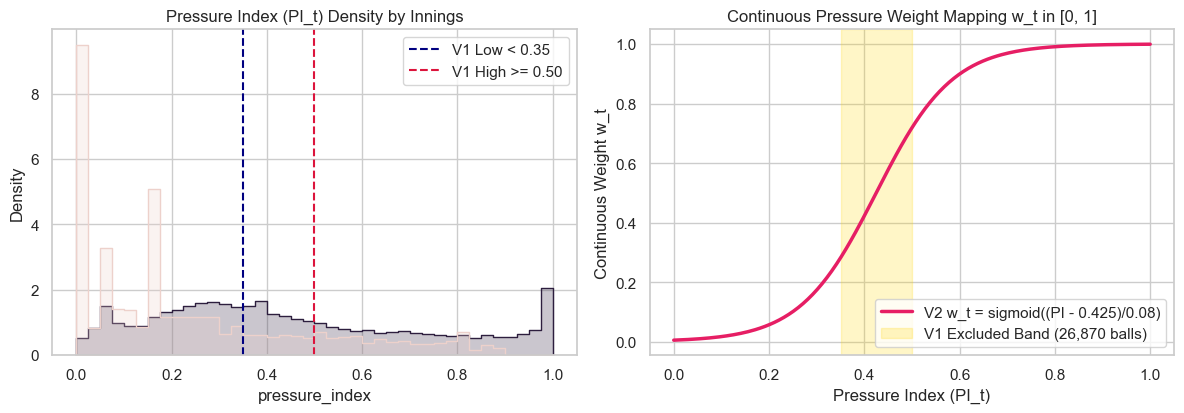

In [2]:
regime_summary = pd.DataFrame([
    {'Band': 'Low Pressure (PI < 0.35)', 'Deliveries': int(df['is_low_pressure'].sum()), 'Share_%': 100.0 * df['is_low_pressure'].mean(), 'Mean_w_t': df.loc[df['is_low_pressure'], 'pressure_weight'].mean()},
    {'Band': 'Intermediate Gap (0.35 <= PI < 0.50)', 'Deliveries': int(df['is_intermediate_pressure'].sum()), 'Share_%': 100.0 * df['is_intermediate_pressure'].mean(), 'Mean_w_t': df.loc[df['is_intermediate_pressure'], 'pressure_weight'].mean()},
    {'Band': 'High Pressure (PI >= 0.50)', 'Deliveries': int(df['is_high_pressure'].sum()), 'Share_%': 100.0 * df['is_high_pressure'].mean(), 'Mean_w_t': df.loc[df['is_high_pressure'], 'pressure_weight'].mean()},
])
print(regime_summary.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sns.histplot(data=df, x='pressure_index', hue='innings', bins=40, stat='density', common_norm=False, element='step', ax=axes[0])
axes[0].axvline(0.35, color='navy', linestyle='--', label='V1 Low < 0.35')
axes[0].axvline(0.50, color='crimson', linestyle='--', label='V1 High >= 0.50')
axes[0].set_title('Pressure Index (PI_t) Density by Innings')
axes[0].legend()

pi_grid = np.linspace(0, 1, 200)
from src.model_v2.pressure_model import compute_pressure_weights
w_grid = compute_pressure_weights(pi_grid)
axes[1].plot(pi_grid, w_grid, color='#E61E64', linewidth=2.5, label='V2 w_t = sigmoid((PI - 0.425)/0.08)')
axes[1].axvspan(0.35, 0.50, color='gold', alpha=0.22, label='V1 Excluded Band (26,870 balls)')
axes[1].set_title('Continuous Pressure Weight Mapping w_t in [0, 1]')
axes[1].set_xlabel('Pressure Index (PI_t)')
axes[1].set_ylabel('Continuous Weight w_t')
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Kish Effective Sample Size (`N_eff`) vs Raw HP Balls

In [3]:
bat = df[df['is_batter_ball_faced']].copy()
bat_neff = grouped_kish_neff(bat, 'striker_id', 'pressure_weight')
bat_stats = (
    bat.groupby('striker_id')
    .agg(
        tot_balls=('runs', 'count'),
        hp_balls_v1=('is_high_pressure', 'sum'),
        lp_balls_v1=('is_low_pressure', 'sum'),
        sum_w=('pressure_weight', 'sum'),
    )
    .join(bat_neff)
    .reset_index()
    .merge(pl.rename(columns={'player_id': 'striker_id'}), on='striker_id', how='left')
)
spot_names = ['Ashutosh Sharma', 'Suryakumar Yadav', 'Tim David', 'Phil Salt', 'Matthew Wade', 'Shai Hope', 'Reeza Hendricks']
print('Spotlight batters — V1 counts vs V2 sum(w_t) and Kish N_eff:')
print(bat_stats[bat_stats['player_name'].isin(spot_names)].sort_values('sum_w', ascending=False)[['striker_id', 'player_name', 'tot_balls', 'hp_balls_v1', 'lp_balls_v1', 'sum_w', 'kish_neff']].round(1).to_string(index=False))

bowl_legal = df[df['is_legal_ball']].copy()
bowl_neff = grouped_kish_neff(bowl_legal, 'bowler_id', 'pressure_weight')
bowl_stats = (
    bowl_legal.groupby('bowler_id')
    .agg(tot_balls=('is_legal_ball', 'count'), hp_balls_v1=('is_high_pressure', 'sum'), lp_balls_v1=('is_low_pressure', 'sum'), sum_w=('pressure_weight', 'sum'))
    .join(bowl_neff)
    .reset_index()
    .merge(pl.rename(columns={'player_id': 'bowler_id'}), on='bowler_id', how='left')
)
spot_bowlers = ['Jasprit Bumrah', 'Sunil Narine', 'Sai Kishore', 'Sufiyan Muqeem', 'Varun Chakravarthy', 'Mohit Sharma']
print('\nSpotlight bowlers — V1 counts vs V2 sum(w_t) and Kish N_eff:')
print(bowl_stats[bowl_stats['player_name'].isin(spot_bowlers)].sort_values('sum_w', ascending=False)[['bowler_id', 'player_name', 'tot_balls', 'hp_balls_v1', 'lp_balls_v1', 'sum_w', 'kish_neff']].round(1).to_string(index=False))

Spotlight batters — V1 counts vs V2 sum(w_t) and Kish N_eff:
 striker_id      player_name  tot_balls  hp_balls_v1  lp_balls_v1  sum_w  kish_neff
       1699 Suryakumar Yadav       2759          657         1694  889.3     1180.5
       6396        Tim David       1226          570          516  641.3      744.3
        768  Reeza Hendricks        835          223          431  314.9      424.9
       8101  Ashutosh Sharma        334          273           42  273.0      290.6
       4369        Shai Hope       1105          128          845  216.5      329.4
       5553        Phil Salt       1643          112         1415  212.9      354.8
        796     Matthew Wade        427          158          184  210.2      254.9



Spotlight bowlers — V1 counts vs V2 sum(w_t) and Kish N_eff:
 bowler_id        player_name  tot_balls  hp_balls_v1  lp_balls_v1  sum_w  kish_neff
      6256 Varun Chakravarthy       2128          803         1030  963.1     1175.6
      2933     Jasprit Bumrah       1708          496          994  623.4      785.1
       781       Sunil Narine       1530          454          855  579.6      739.6
      2878       Mohit Sharma        649          277          293  320.1      370.6
     34485     Sufiyan Muqeem        344          148          130  179.7      214.8
      5577        Sai Kishore        465          123          279  163.1      204.5


## 3. Chronological Pre-Match Elo & LPO Baseline Coverage

In [4]:
elo_long = pd.concat([
    match_elo[['comp_category', 'home_pre_elo']].rename(columns={'home_pre_elo': 'pre_elo'}),
    match_elo[['comp_category', 'away_pre_elo']].rename(columns={'away_pre_elo': 'pre_elo'}),
])
print('Pre-match Elo summary by comp_category:')
print(elo_long.groupby('comp_category')['pre_elo'].describe().round(1))

print('\nOpponent tier distribution across deliveries:')
print(pd.DataFrame({'opp_tier_bat': df['opp_tier_bat'].value_counts(), 'opp_tier_bowl': df['opp_tier_bowl'].value_counts()}))

lpo_cov = pd.DataFrame({
    'bat_deliveries': df['ctx_bat_level'].value_counts().sort_index(),
    'bowl_deliveries': df['ctx_bowl_level'].value_counts().sort_index(),
}).fillna(0).astype(int)
lpo_cov.index.name = 'hierarchy_level'
print('\nLPO Hierarchical Context Baseline Resolution (0 = full 5-way cell, min_cell_n = 50):')
print(lpo_cov)

Pre-match Elo summary by comp_category:
               count    mean   std     min     25%     50%     75%     max
comp_category                                                             
IPL            734.0  1501.7  38.7  1412.6  1472.1  1500.1  1526.3  1602.3
T20I           940.0  1515.3  68.7  1352.1  1470.4  1503.3  1538.5  1747.0

Opponent tier distribution across deliveries:
      opp_tier_bat  opp_tier_bowl
Mid          73603          74264
Low          61911          61812
High         58474          57912

LPO Hierarchical Context Baseline Resolution (0 = full 5-way cell, min_cell_n = 50):
                 bat_deliveries  bowl_deliveries
hierarchy_level                                 
0                        191674           193027
1                          1815              813
2                           499              148
